In [7]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import silhouette_score

In [10]:
# 1. Generate sample data (3 groups of 2D points)
np.random.seed(42)
data1 = np.random.randn(50, 2) + [0, 0]
data2 = np.random.randn(50, 2) + [5, 5]
data3 = np.random.randn(50, 2) + [0, 6]
X = np.vstack([data1, data2, data3])

In [11]:
# Lists to store scores for each K
k_values = range(2, 7)  # Test K = 2, 3, 4, 5, 6 (Silhouette needs at least K=2)
wcss_scores = []
sil_scores = []

In [12]:
# 2. Loop through different values of K to test them
for K in k_values:
  # Pick K random initial centroids
  np.random.seed(42)
  random_indices = np.random.choice(len(X), size=K, replace=False)
  centroids = X[random_indices]

  # Run K-Means loop
  for _ in range(100):
    distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
    labels = np.argmin(distances, axis=1)
    new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(K)])

    if np.allclose(centroids, new_centroids):
      break
    centroids = new_centroids
# --- Calculate Elbow Score (WCSS / Inertia) ---
  wcss = 0
  for k in range(K):
    cluster_points = X[labels == k]
    wcss += np.sum((cluster_points - centroids[k]) ** 2)
  wcss_scores.append(wcss)

  # --- Calculate Silhouette Score ---
  score = silhouette_score(X, labels)
  sil_scores.append(score)

  print(f"K = {K}  |  WCSS (Elbow): {wcss:.2f}  |  Silhouette Score: {score:.3f}")


K = 2  |  WCSS (Elbow): 874.87  |  Silhouette Score: 0.574
K = 3  |  WCSS (Elbow): 285.38  |  Silhouette Score: 0.662
K = 4  |  WCSS (Elbow): 247.25  |  Silhouette Score: 0.526
K = 5  |  WCSS (Elbow): 218.81  |  Silhouette Score: 0.519
K = 6  |  WCSS (Elbow): 191.71  |  Silhouette Score: 0.380


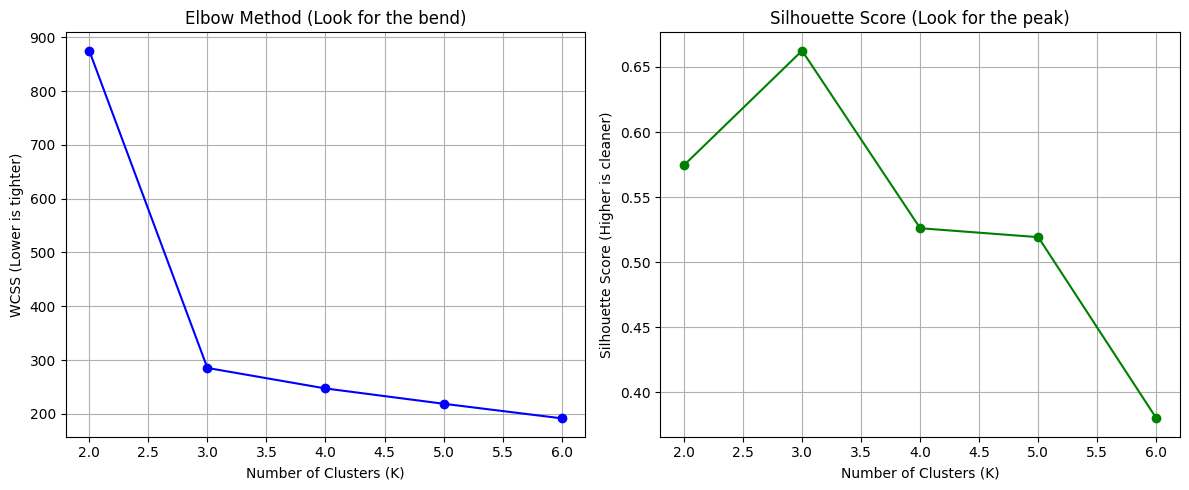

In [13]:
# 3. Plot both graphs side-by-side
plt.figure(figsize=(12, 5))

# Left Plot: Elbow Method
plt.subplot(1, 2, 1)
plt.plot(k_values, wcss_scores, marker="o", color="blue")
plt.title("Elbow Method (Look for the bend)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Lower is tighter)")
plt.grid(True)

# Right Plot: Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(k_values, sil_scores, marker="o", color="green")
plt.title("Silhouette Score (Look for the peak)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score (Higher is cleaner)")
plt.grid(True)

plt.tight_layout()
plt.show()

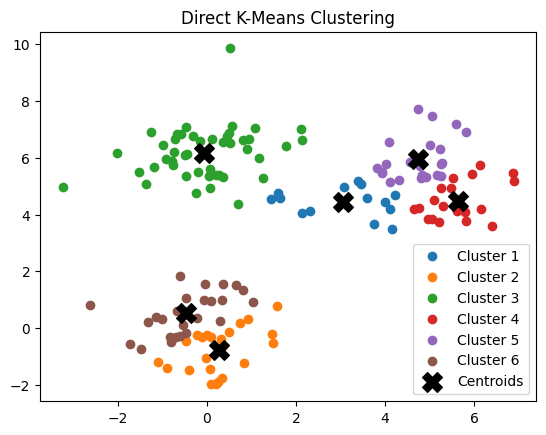

In [14]:
# 6. Plot the clusters
for k in range(K):
  plt.scatter(X[labels == k, 0], X[labels == k, 1], label=f"Cluster {k + 1}")

plt.scatter(centroids[:, 0], centroids[:, 1], color="black", marker="X", s=200, label="Centroids")
plt.title("Direct K-Means Clustering")
plt.legend()
plt.show()